# 04 · Many files, Dask and Zarr

Real datasets rarely come as one small file. Reanalysis and model output arrive as
one file per day, month or year, and a regional 4-D domain easily exceeds the
memory of a laptop. This notebook covers the four steps that make xrMHW work at that
scale:

1. open many files as one dataset with `xr.open_mfdataset`;
2. re-chunk so that time is whole;
3. choose a chunk size from the memory you have;
4. run on a local Dask cluster of worker processes and write the result to Zarr.

The example splits the GLORYS12V1 subset into yearly files to reproduce a typical
download. The numbers are small so the notebook runs in a few minutes; the method
is the one used for the full Grand Banks domain in the xrMHW paper (31 GiB of input
on a 64 GB laptop).

In [1]:
import os
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pooch
import xarray as xr
from dask.distributed import Client, LocalCluster

import xrMHW

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9,
})
INK, INK2 = "#0b0b0b", "#52514e"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("xrmhw"),
    base_url="doi:10.5281/zenodo.22909109/",
    registry={
        "xrmhw_glorys_4d_subset.nc": "md5:5555737e45f1c6cde9f657e50f456693",
        "xrmhw_ostia_sst_3d.nc": "md5:74a2da227394e4463f203f6b388518ee",
    },
)
glorys = xr.open_dataset(EXAMPLE_DATA.fetch("xrmhw_glorys_4d_subset.nc"))

## 1. Make a folder of yearly files

This step only creates the example: one netCDF file per year, with the same
packing as the original. With your own data, start at step 2.

In [2]:
work = Path("xrmhw_outputs")
yearly_dir = work / "glorys_yearly"
if yearly_dir.exists():
    shutil.rmtree(yearly_dir)
yearly_dir.mkdir(parents=True)

encoding = {"thetao": {k: glorys["thetao"].encoding[k]
                       for k in ("dtype", "scale_factor", "add_offset", "_FillValue")}
            | {"zlib": True, "complevel": 1}}
for year, chunk in glorys.groupby("time.year"):
    chunk.to_netcdf(yearly_dir / f"glorys_{year}.nc", encoding=encoding)
files = sorted(yearly_dir.glob("glorys_*.nc"))
print(f"{len(files)} files, {files[0].name} ... {files[-1].name}")

33 files, glorys_1993.nc ... glorys_2025.nc


## 2. Open them as one dataset

`open_mfdataset` reads the metadata of every file and combines them along `time`.
Each file becomes at least one Dask chunk, so **time is split into one chunk per
year**.

In [3]:
mf = xr.open_mfdataset(files, combine="by_coords")
print("time chunks:", mf["thetao"].chunks[0][:4], "...", f"({len(mf['thetao'].chunks[0])} chunks)")

time chunks: (365, 365, 365, 366) ... (33 chunks)


xrMHW refuses this layout, because each cell needs its whole record in one piece
to compute its climatology:

In [4]:
try:
    xrMHW.xrMHW_func(mf, "thetao", clim_period=(1993, 2022))
except ValueError as err:
    print("ValueError:", str(err)[:300], "...")

ValueError: dimension time on 1th function argument to apply_ufunc with dask='parallelized' consists of multiple chunks, but is also a core dimension. To fix, either rechunk into a single array chunk along this dimension, i.e., ``.chunk(dict(time=-1))``, or pass ``allow_rechunk=True`` in ``dask_gufunc_kwargs``  ...


The fix is to re-chunk: one chunk along `time` (`-1`), and split the other
dimensions instead. Re-chunking a dataset read from yearly files is not free: Dask
reads every file once and assembles the full time series of each spatial chunk in
memory, so the spatial chunks must be small enough to fit (step 3). If you process
the same data many times, write the re-chunked input to Zarr once and read that.

In [5]:
ds = mf[["thetao"]].astype("float32").chunk({"time": -1, "depth": 3})
print("time chunks:", ds["thetao"].chunks[0])
print("chunk shape:", ds["thetao"].data.chunksize, "->", ds["thetao"].data.npartitions, "chunks")

time chunks: (12017,)
chunk shape: (12017, 3, 12, 12) -> 11 chunks


## 3. Choose the chunk size from the memory you have

In the xrMHW benchmark, peak memory was about **7.25 times** the decoded size of the
data being processed at once: the input, its climatology and threshold, and the
outputs coexist while a chunk is processed. With `W` worker processes each working on
one chunk, the peak is roughly

$$\text{peak} \approx W \times 7.25 \times \text{chunk size} \;(+\text{2–4 GiB of overhead}).$$

Two rules follow:

- **workers** = physical cores (not logical threads), one thread each;
- **chunk size** ≤ memory per worker / 7.25, and at least two chunks per worker so
  that no worker waits for a slow one.

The helper below applies them. It splits the non-time dimensions from the outermost
inwards until both rules are met.

In [6]:
def plan_chunks(da, n_workers, memory_per_worker_gib, factor=7.25, chunks_per_worker=2):
    """Chunk sizes for xrMHW: time whole, other dimensions split to fit in memory."""
    itemsize = np.dtype("float32").itemsize
    series_bytes = da.sizes["time"] * itemsize               # one cell's full record
    max_cells = max(1, int(memory_per_worker_gib * 2**30 / (factor * series_bytes)))
    other = [d for d in da.dims if d != "time"]
    n_cells = int(np.prod([da.sizes[d] for d in other]))
    target_chunks = max(int(np.ceil(n_cells / max_cells)), n_workers * chunks_per_worker)

    chunks, remaining = {"time": -1}, target_chunks
    for d in other:                      # outermost first
        pieces = min(da.sizes[d], remaining)
        chunks[d] = int(np.ceil(da.sizes[d] / pieces))
        remaining = int(np.ceil(remaining / pieces))
    return chunks


n_workers = min(4, os.cpu_count() or 1)
memory_per_worker = 1.5          # GiB; set this from your machine
plan = plan_chunks(ds["thetao"], n_workers, memory_per_worker)
ds = ds.chunk(plan)
chunk_mib = np.prod(ds["thetao"].data.chunksize) * 4 / 2**20
print(f"{n_workers} workers, {memory_per_worker} GiB each -> chunks {plan}")
print(f"{ds['thetao'].data.npartitions} chunks of {chunk_mib:.0f} MiB; "
      f"expected peak per worker about {7.25 * chunk_mib / 1024:.2f} GiB")

4 workers, 1.5 GiB each -> chunks {'time': -1, 'depth': 5, 'latitude': 12, 'longitude': 12}
7 chunks of 33 MiB; expected peak per worker about 0.23 GiB


For your own data, replace `n_workers` and `memory_per_worker` with your machine's
values and leave some memory for the operating system. As an example, the full Grand
Banks domain (31 GiB decoded) ran on 14 workers with 176 MiB chunks, a peak of 22 GiB.

## 4. Run on a local cluster of processes

Dask's default scheduler uses threads. xrMHW's per-cell kernel is NumPy and SciPy
code that holds Python's global interpreter lock part of the time, so threads scale
only partly. Separate **processes**, one thread each, scale with the number of cores.
`LocalCluster` starts them on your machine, and its dashboard shows progress and
memory per worker.

In [7]:
cluster = LocalCluster(n_workers=n_workers, threads_per_worker=1,
                       memory_limit=f"{memory_per_worker}GiB")
client = Client(cluster)
print("dashboard:", client.dashboard_link)

dashboard: http://127.0.0.1:8787/status


The detection stays lazy until the write asks for values. Writing to **Zarr**
computes and stores each chunk as soon as it is ready, so the full result never
has to fit in memory.

In [8]:
zarr_path = work / "glorys_mhw.zarr"
if zarr_path.exists():
    shutil.rmtree(zarr_path)

result = xrMHW.xrMHW_func(ds, "thetao", clim_period=(1993, 2022))
t0 = time.perf_counter()
result.to_zarr(zarr_path, mode="w", consolidated=False)
elapsed = time.perf_counter() - t0
steps = ds["thetao"].size
print(f"detection and write: {elapsed:.0f} s, "
      f"{steps / elapsed / 1e6:.1f} million grid-cell time steps per second")

detection and write: 9 s, 6.0 million grid-cell time steps per second


### Why Zarr

Two reasons.

**It works with worker processes.** Writing netCDF from several processes at once
relies on file locks, and in the xrMHW benchmark a large write from 14 processes
failed with a netCDF error after a few gigabytes. Zarr stores every chunk as a
separate object, so workers write in parallel without locks. If you need netCDF,
write the Zarr store first and convert it, or compute a result that fits in memory
and then call `to_netcdf`.

**It compresses by default.** The event fields are NaN outside events, most of the
time. Compressed, they take a small fraction of their size in memory:

In [9]:
def folder_size(path):
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file())


print(f"results in memory (uncompressed): {result.nbytes / 2**30:.2f} GiB")
print(f"Zarr store on disk:               {folder_size(zarr_path) / 2**30:.2f} GiB")

results in memory (uncompressed): 1.70 GiB
Zarr store on disk:               0.05 GiB


## 5. Work from the stored result

`xr.open_zarr` opens the store lazily, so analyses read only what they need. Here,
the share of water cells in a marine heatwave, per year and in three depth layers
(a share of cells, not of volume: levels get thicker with depth).

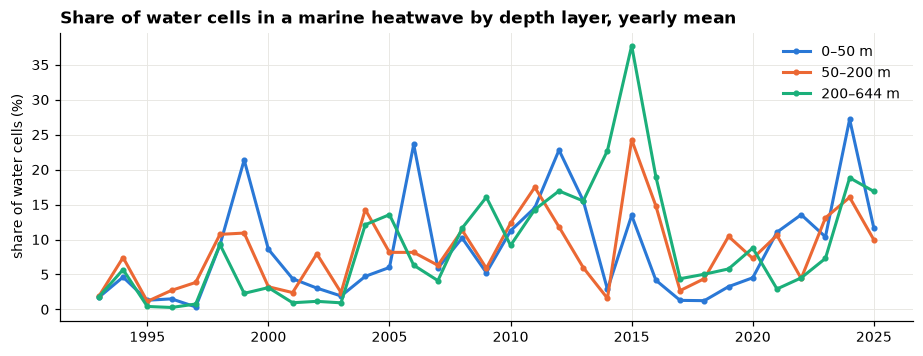

In [10]:
stored = xr.open_zarr(zarr_path, consolidated=False)
water = glorys["thetao"].isel(time=0).notnull()
layers = {"0–50 m": slice(0, 50), "50–200 m": slice(50, 200), "200–644 m": slice(200, 700)}

fig, ax = plt.subplots(figsize=(10, 3.4))
for (name, zs), color in zip(layers.items(), [BLUE, ORANGE, AQUA]):
    m = stored["mhw_severity"].sel(depth=zs).notnull()
    w = water.sel(depth=zs)
    share = (m.where(w).sum(("depth", "latitude", "longitude")) / w.sum()).groupby(
        "time.year").mean().compute()
    ax.plot(share.year, 100 * share, color=color, lw=2, marker="o", ms=3, label=name)
ax.set_ylabel("share of water cells (%)")
ax.set_title("Share of water cells in a marine heatwave by depth layer, yearly mean", loc="left")
ax.legend(frameon=False)
ax.grid(color="#e7e6e2", lw=0.6)
plt.show()

Close the cluster when you are done, so the worker processes release their memory.

In [11]:
client.close()
cluster.close()

## Summary

- `open_mfdataset` splits time by file; re-chunk with `{"time": -1}` before xrMHW.
- Size chunks from memory: chunk ≤ memory per worker / 7.25, at least two chunks per
  worker, one worker per physical core.
- Use a `LocalCluster` of processes with one thread each, and write to Zarr.

Next: **05 · Troubleshooting**.